In [1]:
#!pip -q install medmnist


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from medmnist import PathMNIST, INFO

warnings.filterwarnings('ignore')

from sklearn.neighbors import NearestNeighbors
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [3]:
SEED = 21

# Set Python, NumPy and TensorFlow random seeds.
keras.utils.set_random_seed(SEED)

# Request deterministic TensorFlow operations where supported.
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Determinism setting unavailable:", e)

Image shape: (89996, 28, 28, 3)
Image dtype: uint8
Pixel range: 0 to 255
Label shape: (89996,)
Class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8], dtype=uint8), array([ 9366,  9509, 10360, 10401,  8006, 12182,  7886,  9401, 12885]))
Class mapping: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


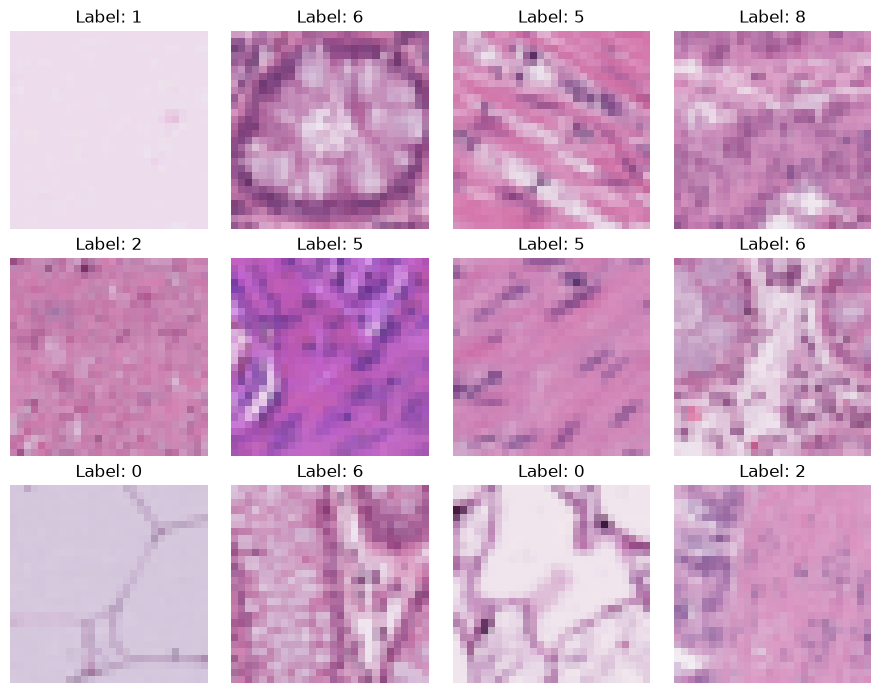

In [4]:

# Begin at 28x28 to keep the first run close to our MNIST DCGAN.
train_ds = PathMNIST(
    split="train",
    size=28,
    download=True
)

X = train_ds.imgs
y = train_ds.labels.squeeze()

print("Image shape:", X.shape)
print("Image dtype:", X.dtype)
print("Pixel range:", X.min(), "to", X.max())
print("Label shape:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

# Inspect the class names documented by MedMNIST.
print("Class mapping:", INFO["pathmnist"]["label"])

# Visual audit: view some real examples before training.
fig, axes = plt.subplots(3, 4, figsize=(9, 7))

for ax in axes.flat:
    i = np.random.randint(len(X))
    ax.imshow(X[i])
    ax.set_title(f"Label: {int(y[i])}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
target_label = 8

class_mask = (y == target_label)

X_train_raw = X[class_mask]

print("Selected class:", target_label)
print("Selected images:", len(X_train_raw))
print("Image shape:", X_train_raw.shape)

Selected class: 8
Selected images: 12885
Image shape: (12885, 28, 28, 3)


In [6]:
X_train = (X_train_raw.astype('float32') - 127.5) / 127.5

print("Normalized range:", X_train.min(), X_train.max())
print("Normalized dtype:", X_train.dtype)

Normalized range: -0.99215686 0.9843137
Normalized dtype: float32


In [7]:
BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(buffer_size= len(X_train), seed= SEED, reshuffle_each_iteration= True).batch(
    BATCH_SIZE, drop_remainder= True).prefetch(tf.data.AUTOTUNE)


print("Batch shape:", next(iter(train_dataset)).shape)
print("Steps per epoch:", len(X_train) // BATCH_SIZE)

Batch shape: (32, 28, 28, 3)
Steps per epoch: 402


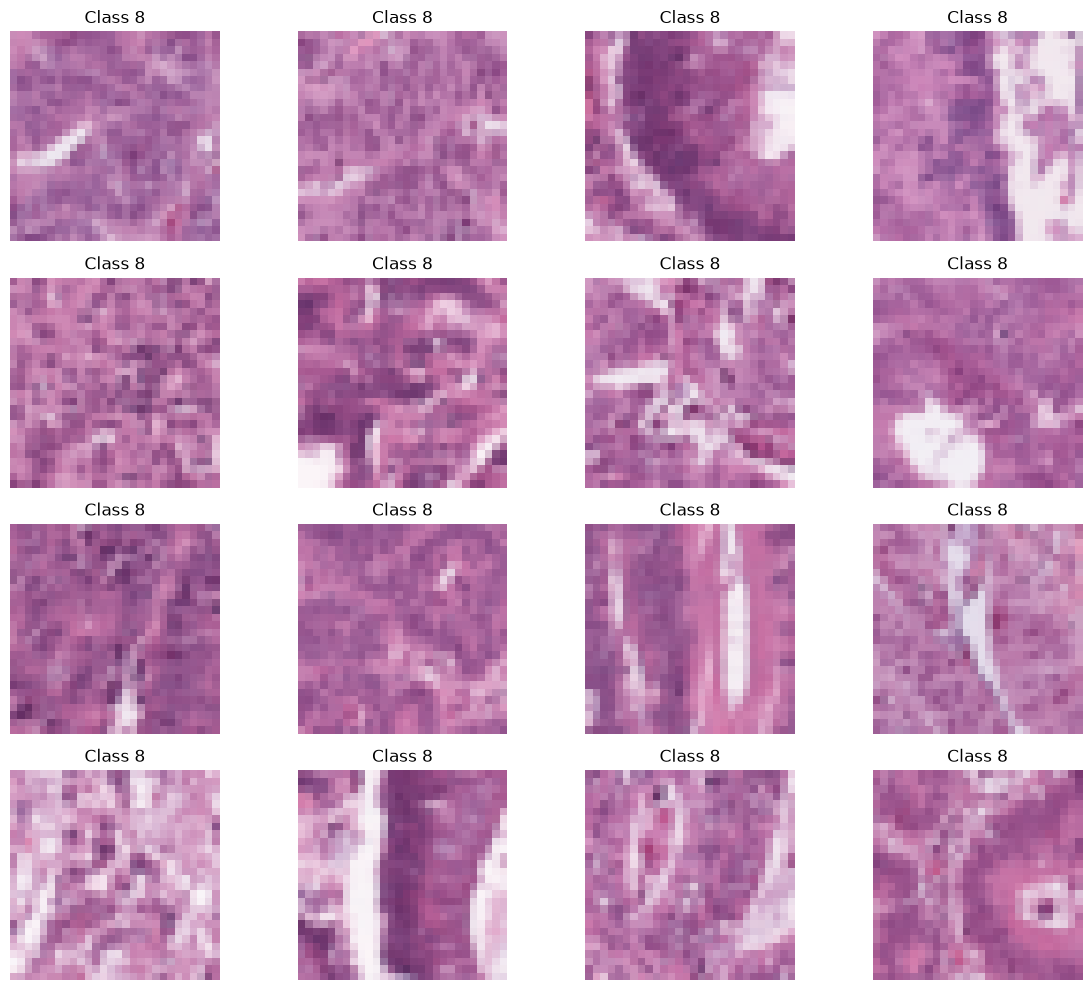

In [8]:
fig, axes = plt.subplots(4 , 4, figsize = (12 , 10))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train_raw[i])
    ax.set_title(f'Class {target_label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

## Building Generator

In [9]:
LATENT_DIM = 100

def build_generator(latent_dim = LATENT_DIM):
    model = keras.Sequential([
        keras.Input(shape = (LATENT_DIM,)),
        layers.Dense(7  * 7 * 256, use_bias= False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7 , 256)),

        layers.Conv2DTranspose(128, kernel_size= 5 , strides= 1 , padding= 'same', use_bias= False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, kernel_size= 5, strides= 2 , padding= 'same', use_bias= False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(3, kernel_size= 5 , strides= 2 , padding = 'same', use_bias= False, activation= 'tanh')
    ], name = 'generator')

    return model

generator = build_generator()

generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 3)      │         4,800 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,334,144 (8.90 MB)

 Trainable params: 2,308,672 (8.81 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [10]:
noise = tf.random.normal(shape=(4 , LATENT_DIM), seed = SEED)

generated_images = generator(noise, training = False)

print('Outputed Image Shape: ', generated_images.shape)

print(
    "Output range:",
    float(tf.reduce_min(generated_images)),
    float(tf.reduce_max(generated_images))
)

Outputed Image Shape:  (4, 28, 28, 3)
Output range: -0.07622689008712769 0.09715639054775238


Let's visualize the generated images

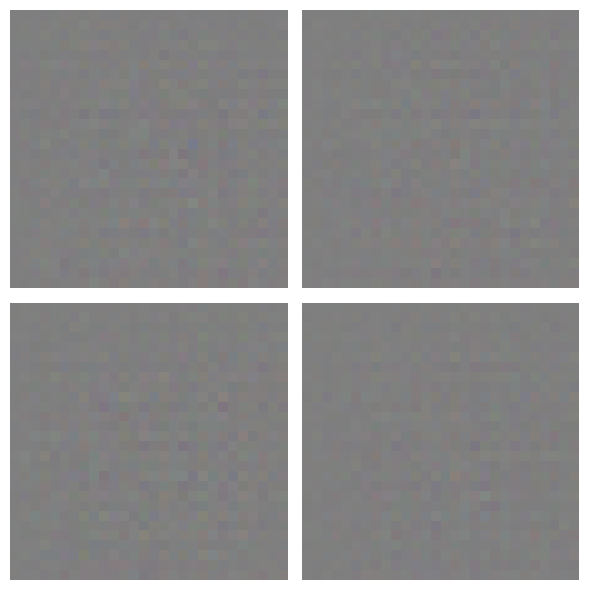

In [11]:
gen_images = (generated_images.numpy() + 1) / 2

fig, axes = plt.subplots(2 , 2 , figsize = (6 , 6))

for i , ax in enumerate(axes.flat):
    ax.imshow(np.clip(gen_images[i], -1 , 1))
    ax.axis('off')

plt.tight_layout()
plt.show()

## Building Discriminator

In [12]:
def build_discriminator(img_shape = (28 , 28 , 3)):
    model = keras.Sequential([
        keras.Input(shape= (img_shape)),
        layers.Conv2D(64, kernel_size= 5, strides= 2, padding= 'same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, kernel_size= 5 , strides= 2 , padding= 'same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name = 'discriminator')

    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,065 (844.00 KB)

 Trainable params: 216,065 (844.00 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
real_batch = next(iter(train_dataset))

real_logits = discriminator(real_batch, training = False)

fake_logits = discriminator(gen_images, training = False)

print("Real logits shape:", real_logits.shape)
print("Fake logits shape:", fake_logits.shape)

print("Real logits:", real_logits.numpy().flatten())
print("Fake logits:", fake_logits.numpy().flatten())

Real logits shape: (32, 1)
Fake logits shape: (4, 1)
Real logits: [-2.6377965e-02 -9.3177706e-03  1.5348021e-02 -4.5883253e-02
 -3.9528079e-02 -3.0325955e-02 -2.7025769e-02  1.5704472e-02
 -5.9231024e-02 -2.2295870e-02  3.5229247e-02  4.6923272e-03
 -8.5014571e-03 -1.7022088e-02 -4.4415429e-02 -8.6768985e-02
 -6.1896145e-02  6.2897861e-02 -8.1748255e-02 -2.8297305e-05
 -7.8714103e-02 -5.3676706e-02 -4.3350101e-02  3.6796676e-03
 -5.1699638e-02 -5.2496213e-02 -5.0216265e-02 -3.6995489e-02
 -1.1609262e-02 -1.6155647e-02  1.2961743e-02 -4.2086847e-02]
Fake logits: [-0.06442384 -0.06052329 -0.06283315 -0.06342922]


In [14]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits= True)

## Generator Loss

In [15]:
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)


## Discriminator Loss

In [16]:
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)

    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)

    total_loss = real_loss + fake_loss

    return total_loss

## Initializing the optimizers

In [17]:
generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

Let's test the loss functions to see if they work correctly

In [18]:
real_output = discriminator(real_batch, training = True)

fake_output = discriminator(generated_images, training = True)

g_loss = generator_loss(fake_output)

d_loss = discriminator_loss(real_output , fake_output)

print("Real output shape:", real_output.shape)
print("Fake output shape:", fake_output.shape)

print("Generator loss:", float(g_loss))
print("Discriminator loss:", float(d_loss))

Real output shape: (32, 1)
Fake output shape: (4, 1)
Generator loss: 0.6953103542327881
Discriminator loss: 1.3953593969345093


## Defining the train function

In [19]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal(shape= (batch_size, LATENT_DIM))

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training = True)

        real_output = discriminator(real_images, training = True)
        fake_output = discriminator(generated_images, training = True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

    

In [20]:
real_batch = next(iter(train_dataset))

g_loss, d_loss = train_step(real_batch)

print("Generator loss:", float(g_loss))
print("Discriminator loss:", float(d_loss))

Generator loss: 0.7148257493972778
Discriminator loss: 1.3784977197647095


## Training the model

In [21]:
NUM_EXAMPLES = 16

fixed_noise = tf.random.stateless_normal(
    shape=(NUM_EXAMPLES, LATENT_DIM),
    seed=[SEED, 2026]
)

In [22]:
def generate_save_images(model, epoch, noise):
    prediction = model(noise, training = False)
    prediction = (prediction.numpy() + 1 ) / 2
    prediction = np.clip(prediction, 0 , 1)

    fig, axes = plt.subplots(4 , 4 , figsize = (8 , 8))

    for i , ax in enumerate(axes.flat):
        ax.imshow(prediction[i])
        ax.axis('off')

    fig.suptitle(f'Epoch {epoch}')
    plt.tight_layout()
    plt.show()

Epoch 1/20 | G Loss: 0.7502 | D Loss: 1.3339


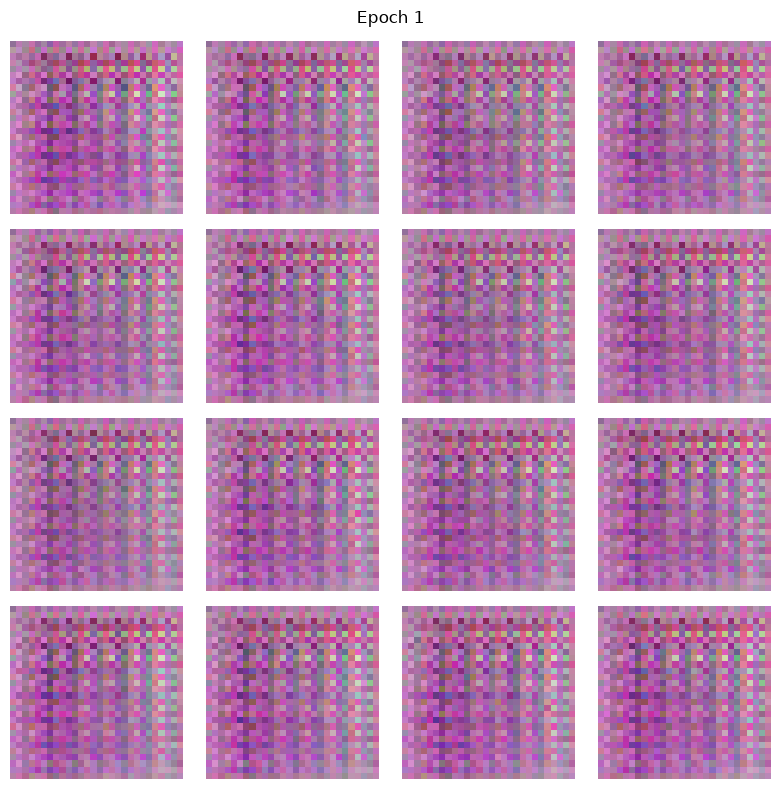

Epoch 2/20 | G Loss: 0.8143 | D Loss: 1.2176


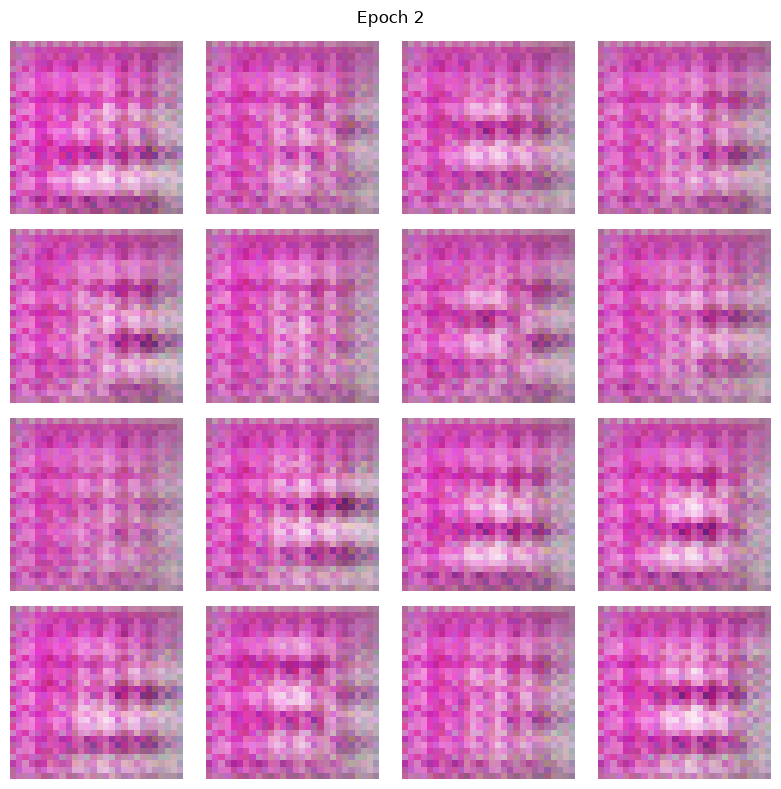

Epoch 3/20 | G Loss: 0.7842 | D Loss: 1.2792


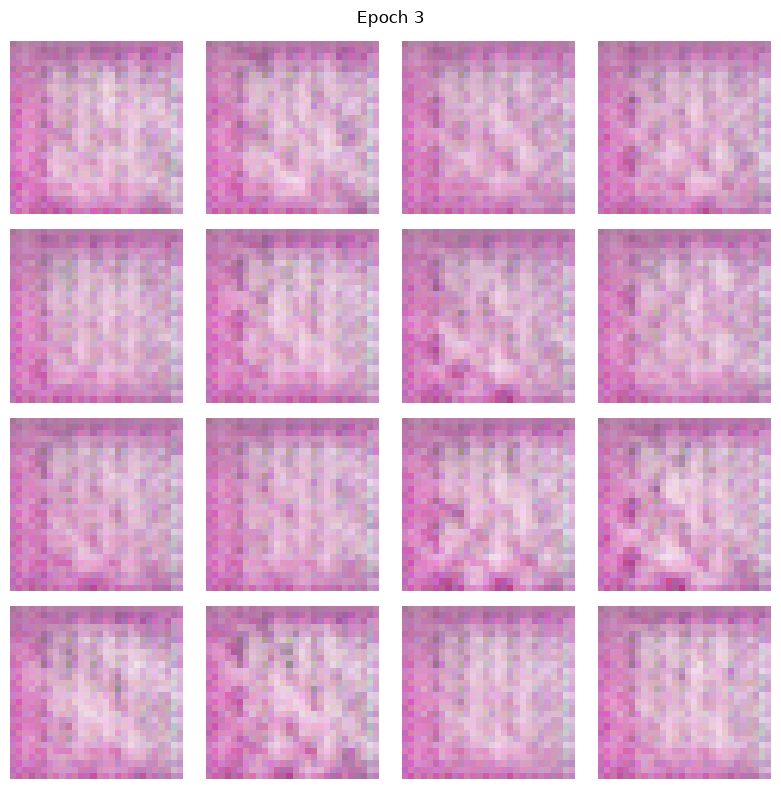

Epoch 4/20 | G Loss: 0.8523 | D Loss: 1.2251


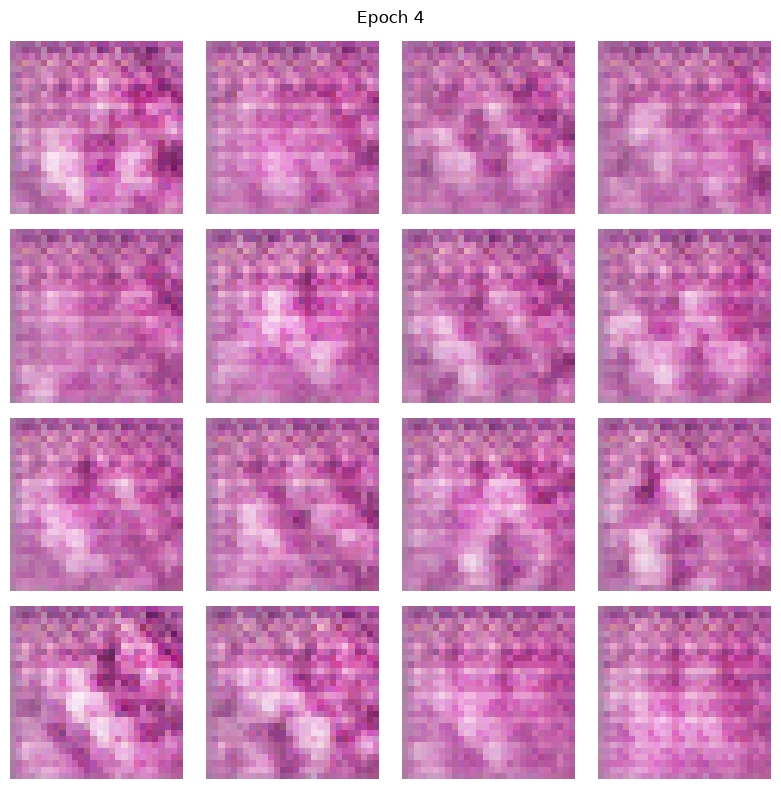

Epoch 5/20 | G Loss: 0.8849 | D Loss: 1.1786


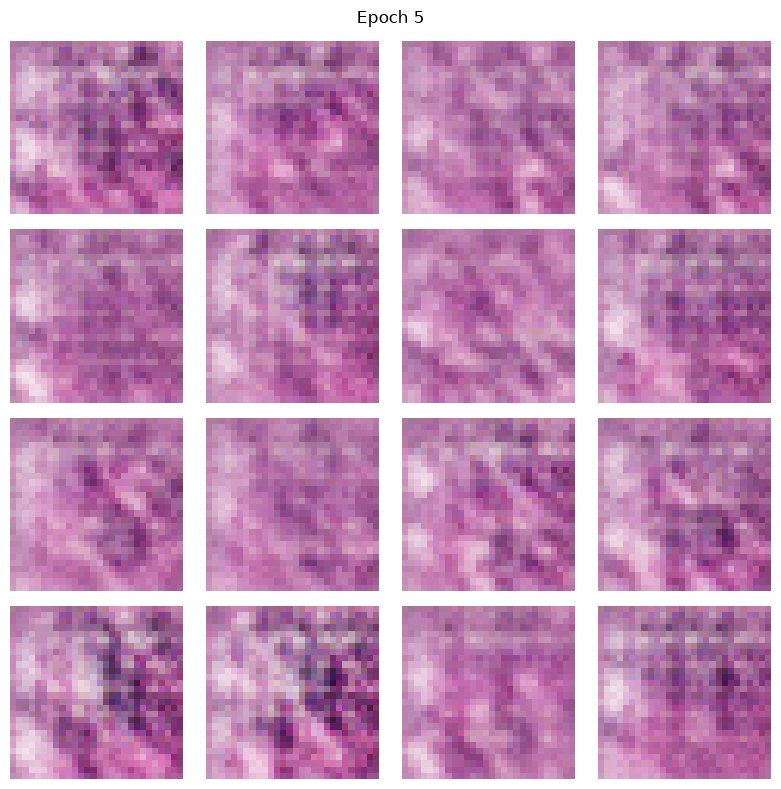

Epoch 6/20 | G Loss: 0.7681 | D Loss: 1.3295


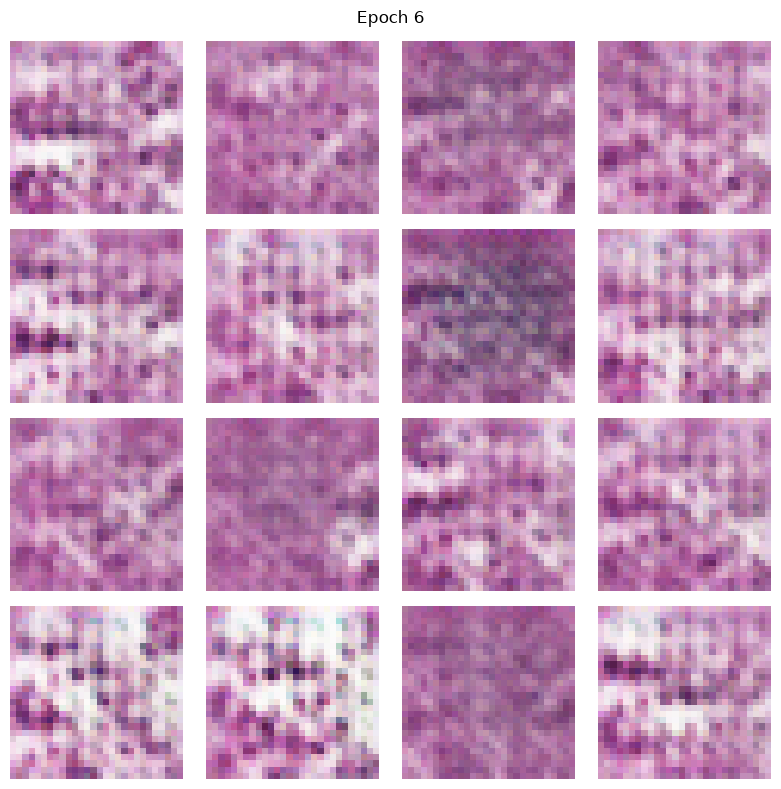

Epoch 7/20 | G Loss: 0.7531 | D Loss: 1.3433


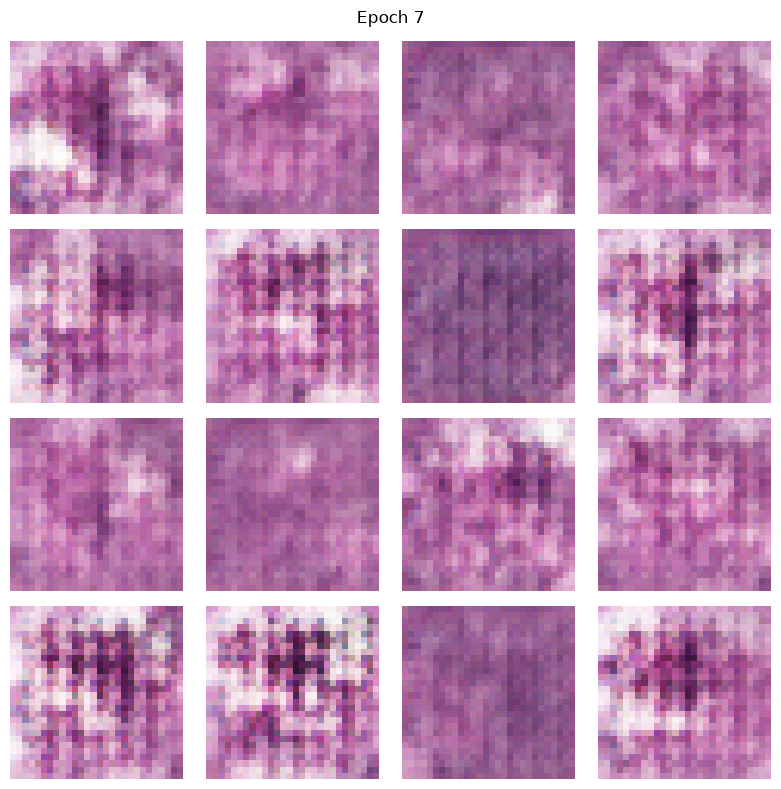

Epoch 8/20 | G Loss: 0.7624 | D Loss: 1.3327


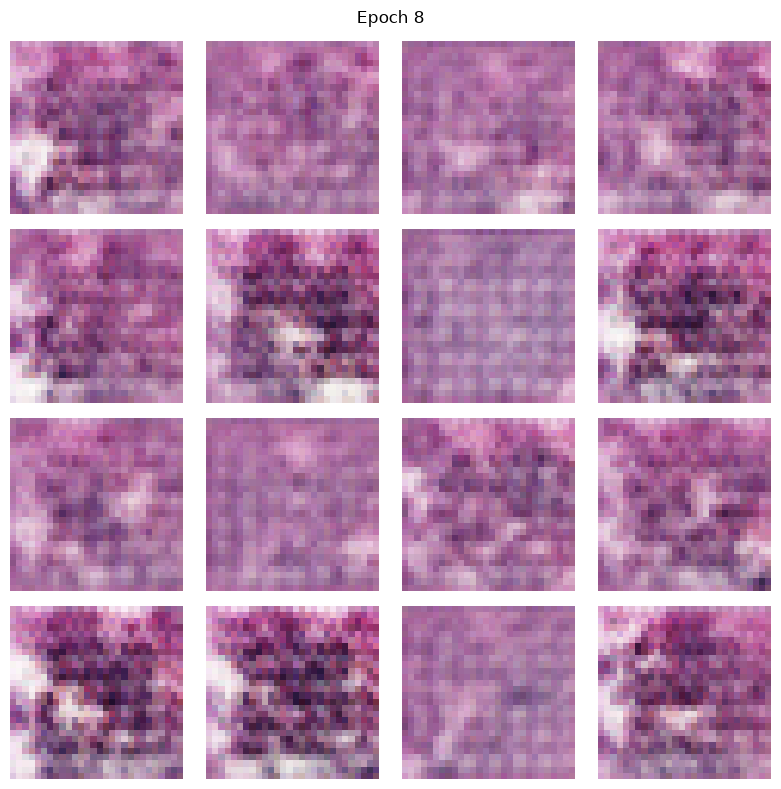

Epoch 9/20 | G Loss: 0.7681 | D Loss: 1.3283


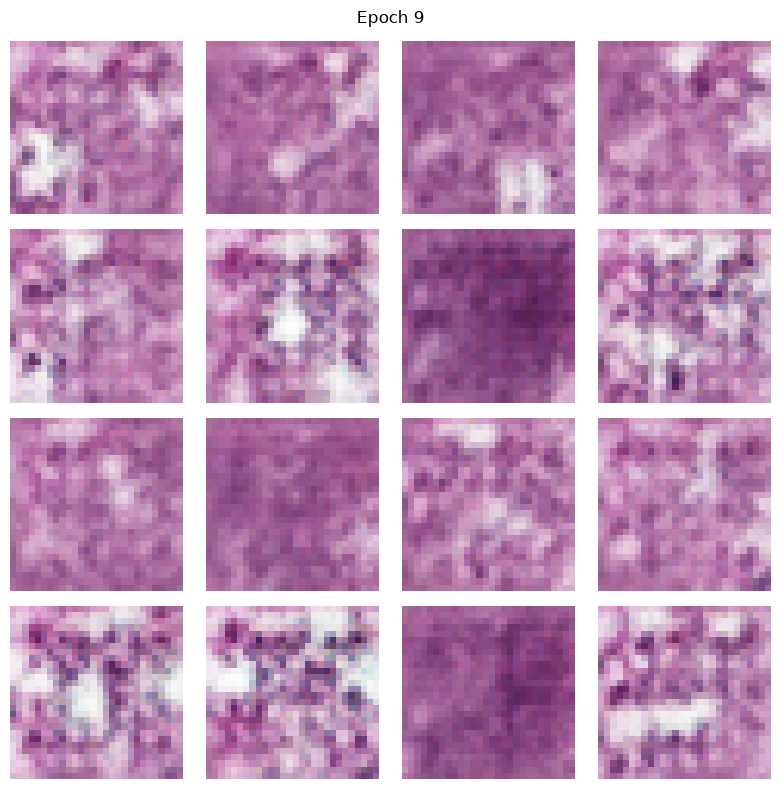

Epoch 10/20 | G Loss: 0.7529 | D Loss: 1.3408


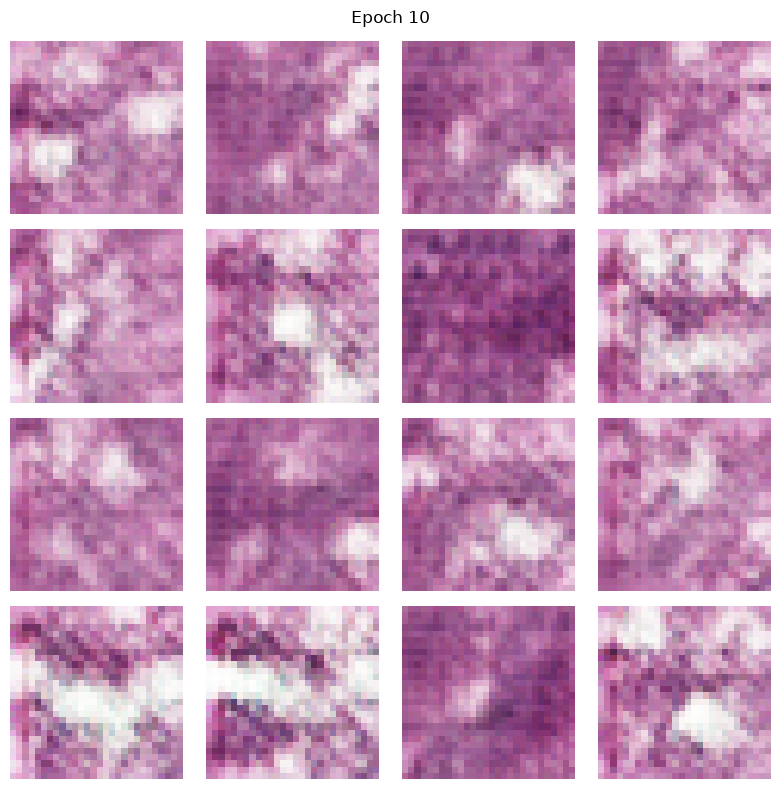

Epoch 11/20 | G Loss: 0.7557 | D Loss: 1.3444


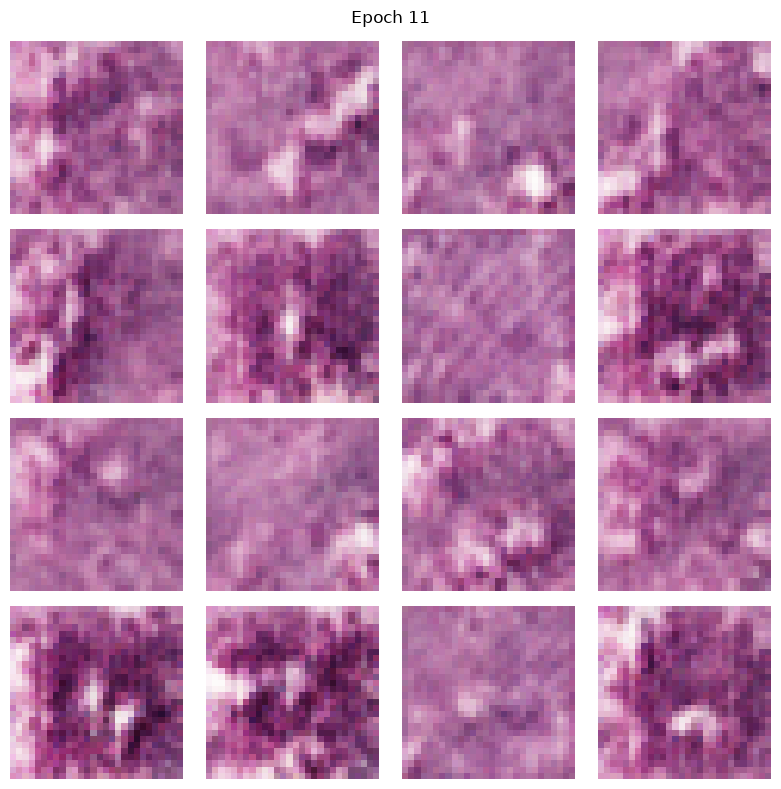

Epoch 12/20 | G Loss: 0.7371 | D Loss: 1.3595


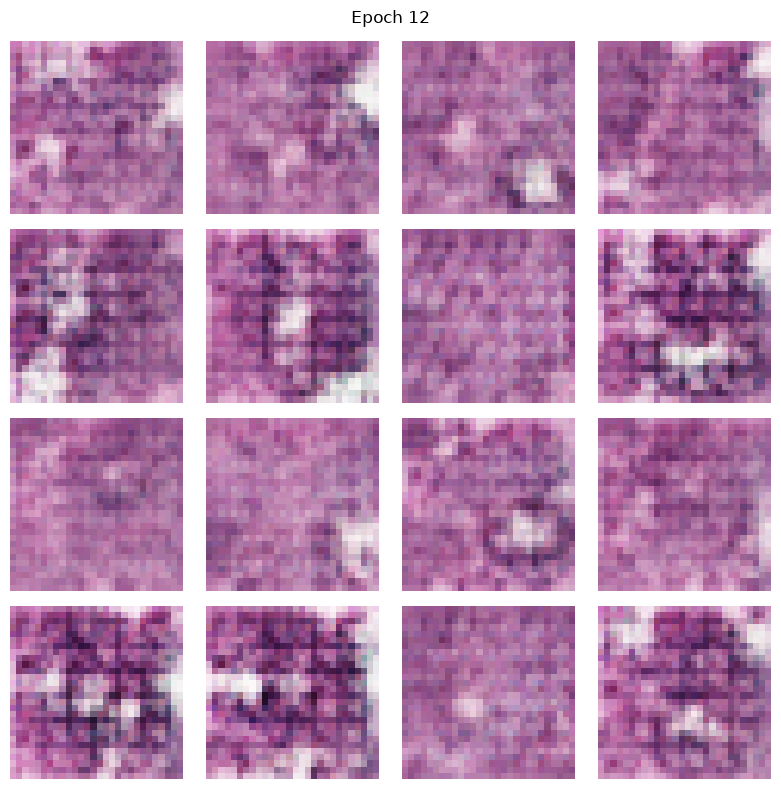

Epoch 13/20 | G Loss: 0.7173 | D Loss: 1.3852


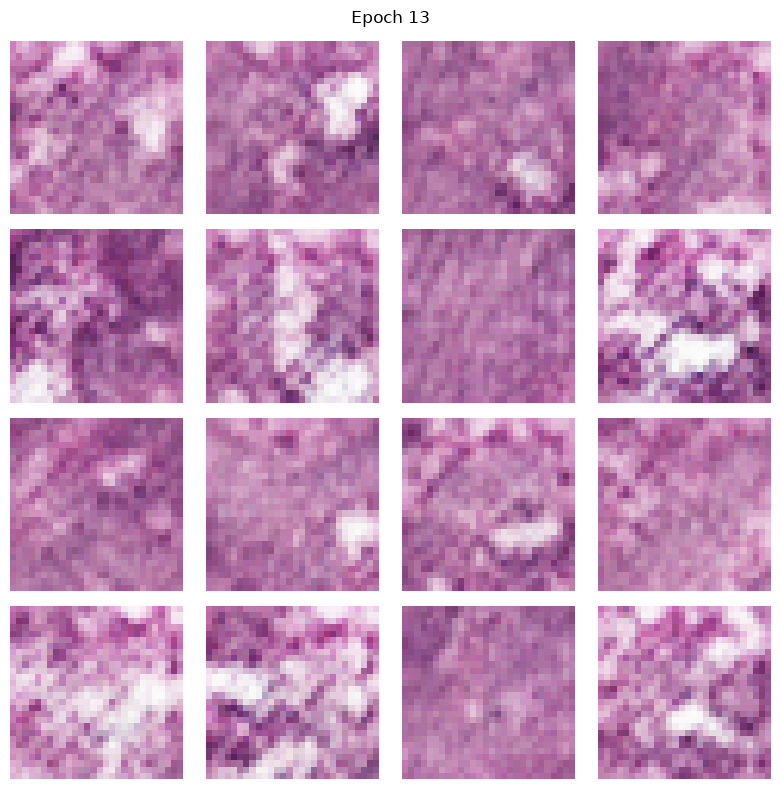

Epoch 14/20 | G Loss: 0.7039 | D Loss: 1.3951


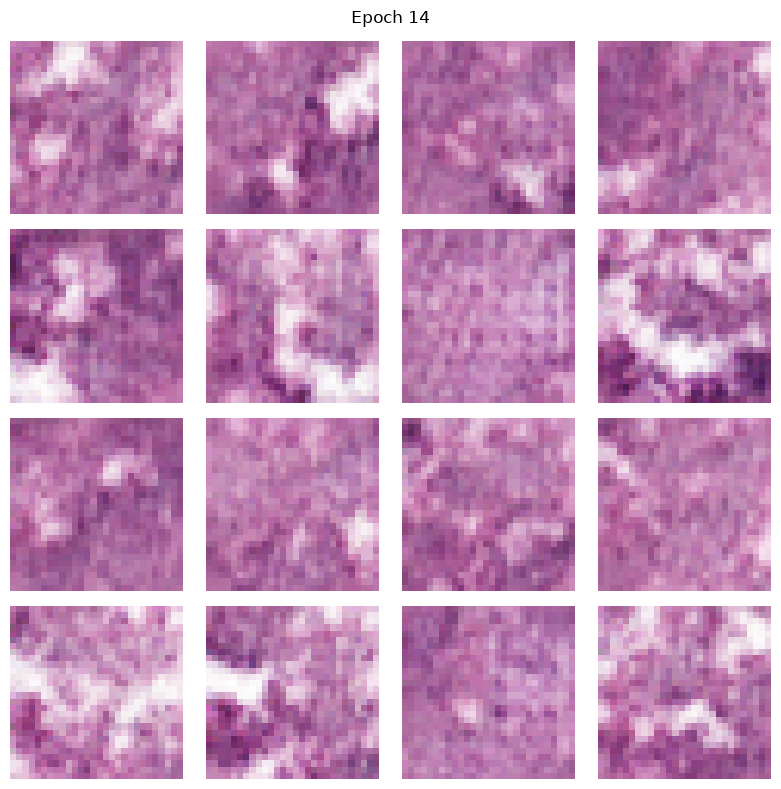

Epoch 15/20 | G Loss: 0.7018 | D Loss: 1.3946


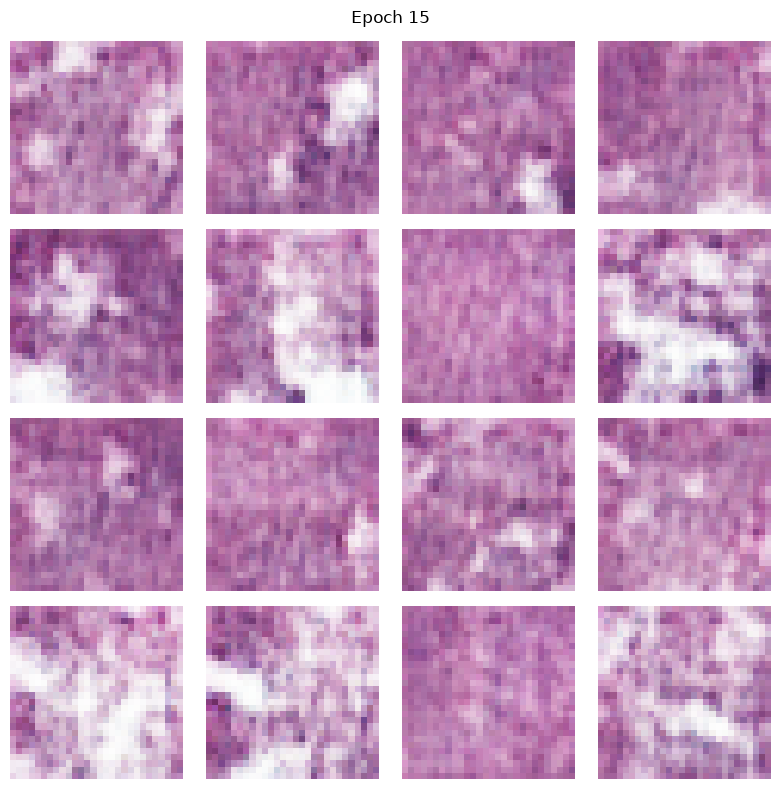

Epoch 16/20 | G Loss: 0.7011 | D Loss: 1.3936


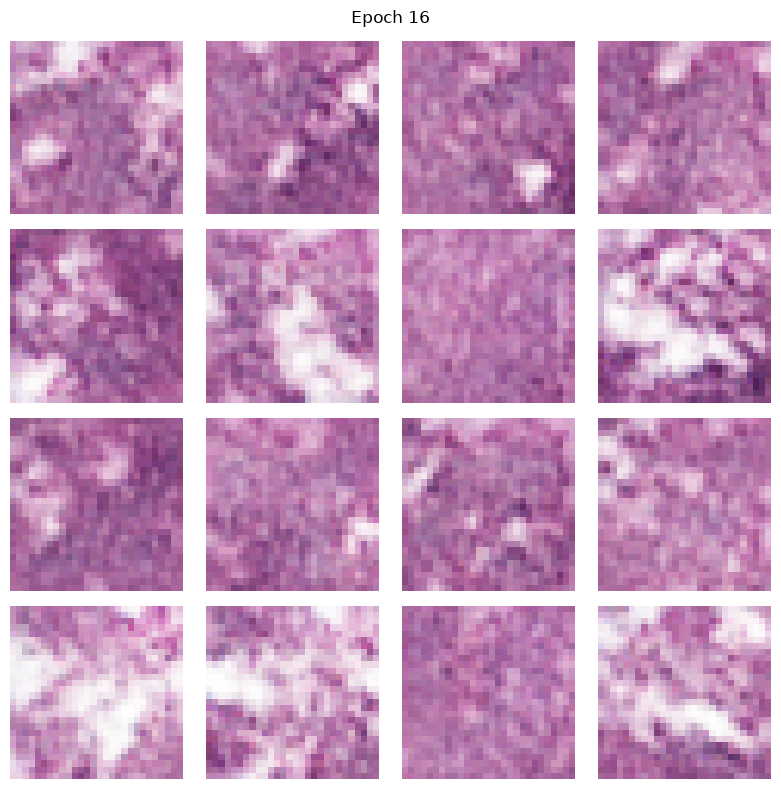

Epoch 17/20 | G Loss: 0.7037 | D Loss: 1.3895


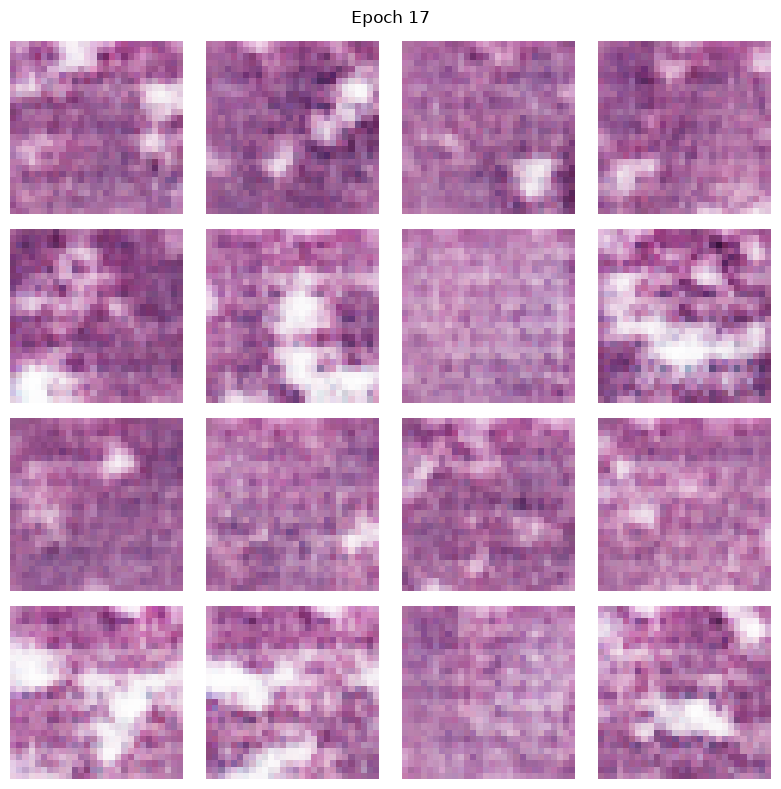

Epoch 18/20 | G Loss: 0.7008 | D Loss: 1.3910


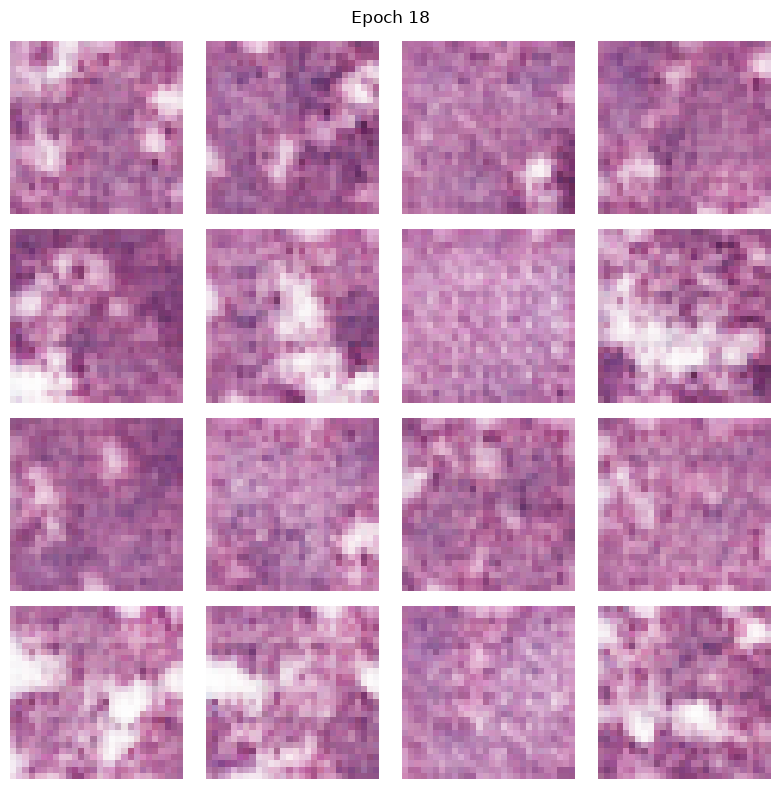

Epoch 19/20 | G Loss: 0.7035 | D Loss: 1.3881


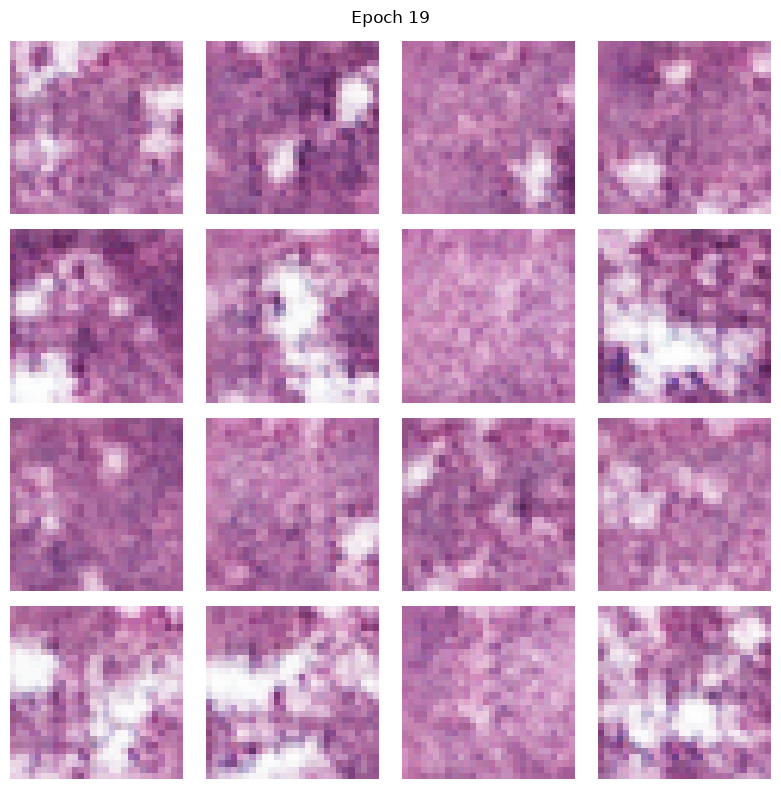

Epoch 20/20 | G Loss: 0.7010 | D Loss: 1.3890


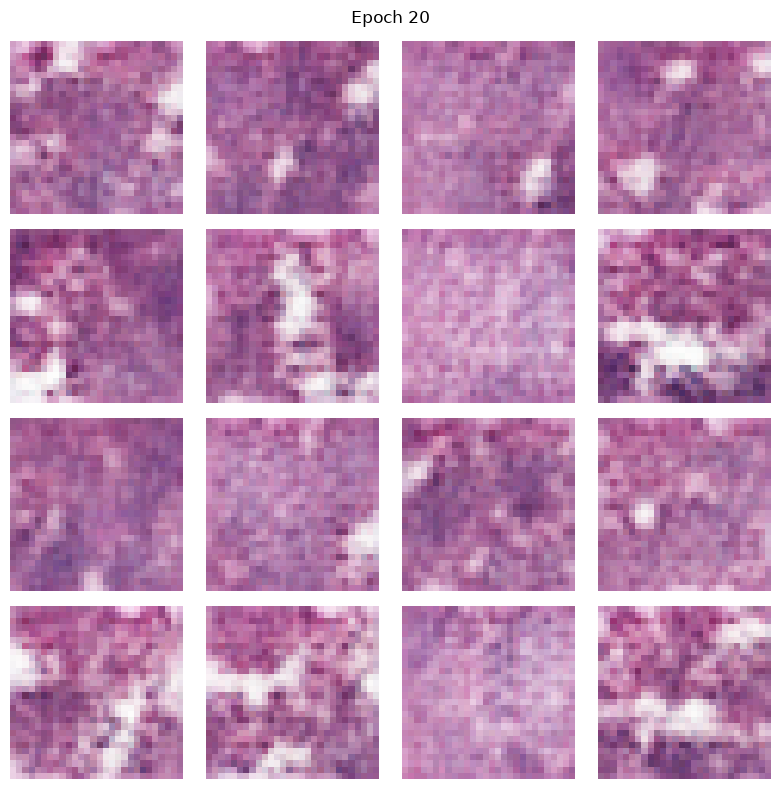

In [23]:
EPOCHS = 20

history = {
    "generator_loss": [],
    "discriminator_loss": []
}

for epoch in range(EPOCHS):

    gen_metric = keras.metrics.Mean()
    disc_metric = keras.metrics.Mean()

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        gen_metric.update_state(g_loss)
        disc_metric.update_state(d_loss)

    epoch_g_loss = float(gen_metric.result())
    epoch_d_loss = float(disc_metric.result())

    history["generator_loss"].append(epoch_g_loss)
    history["discriminator_loss"].append(epoch_d_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"G Loss: {epoch_g_loss:.4f} | "
        f"D Loss: {epoch_d_loss:.4f}"
    )

    generate_save_images(
        generator,
        epoch + 1,
        fixed_noise
    )

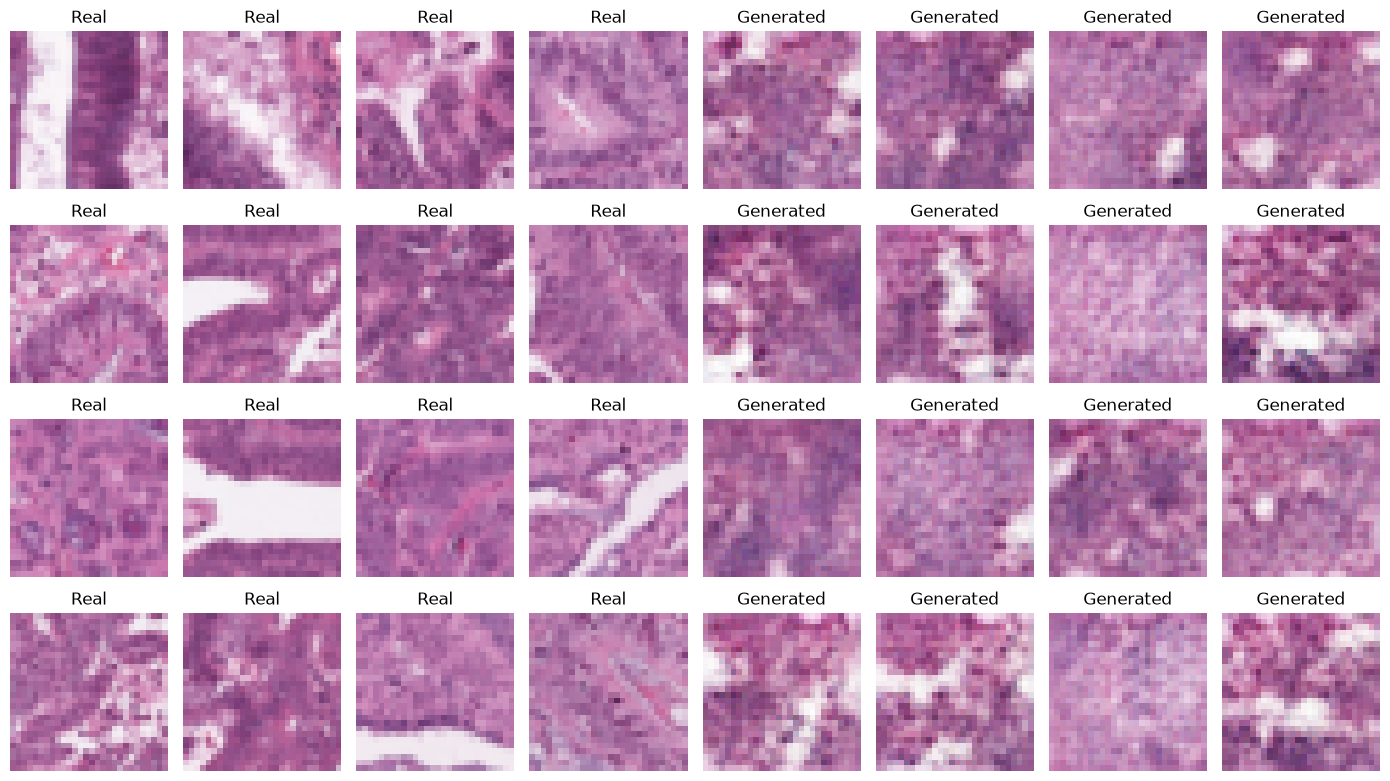

In [24]:
# Generate 16 images.
generated = generator(
    fixed_noise,
    training=False
).numpy()

generated = (generated + 1) / 2
generated = np.clip(generated, 0, 1)

# Select 16 real images.
rng = np.random.default_rng(SEED)

indices = rng.choice(
    len(X_train_raw),
    size=16,
    replace=False
)

real = X_train_raw[indices]

# Display side by side.
fig, axes = plt.subplots(4, 8, figsize=(14, 8))

for i in range(16):

    # Real images: first four columns.
    axes[i // 4, i % 4].imshow(real[i])
    axes[i // 4, i % 4].set_title("Real")
    axes[i // 4, i % 4].axis("off")

    # Generated images: last four columns.
    axes[i // 4, 4 + i % 4].imshow(generated[i])
    axes[i // 4, 4 + i % 4].set_title("Generated")
    axes[i // 4, 4 + i % 4].axis("off")

plt.tight_layout()
plt.show()

These images look promising and they are definetly look like histopathological images, although some might be a little bit off, but given our simple DCGAN model, they are acceptable.

In [25]:
checkpoint = tf.train.Checkpoint(
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

manager = tf.train.CheckpointManager(
    checkpoint,
    "./pathmnist_dcgan_checkpoints",
    max_to_keep=5
)

manager.save(checkpoint_number=20)

'./pathmnist_dcgan_checkpoints\\ckpt-20'

What happens if we continue training beyond 20 epochs? let's do it for another 10 epochs

Epoch 21/30 | G Loss: 0.7043 | D Loss: 1.3889
Epoch 22/30 | G Loss: 0.7006 | D Loss: 1.3864
Epoch 23/30 | G Loss: 0.7044 | D Loss: 1.3826
Epoch 24/30 | G Loss: 0.7060 | D Loss: 1.3839
Epoch 25/30 | G Loss: 0.7023 | D Loss: 1.3855


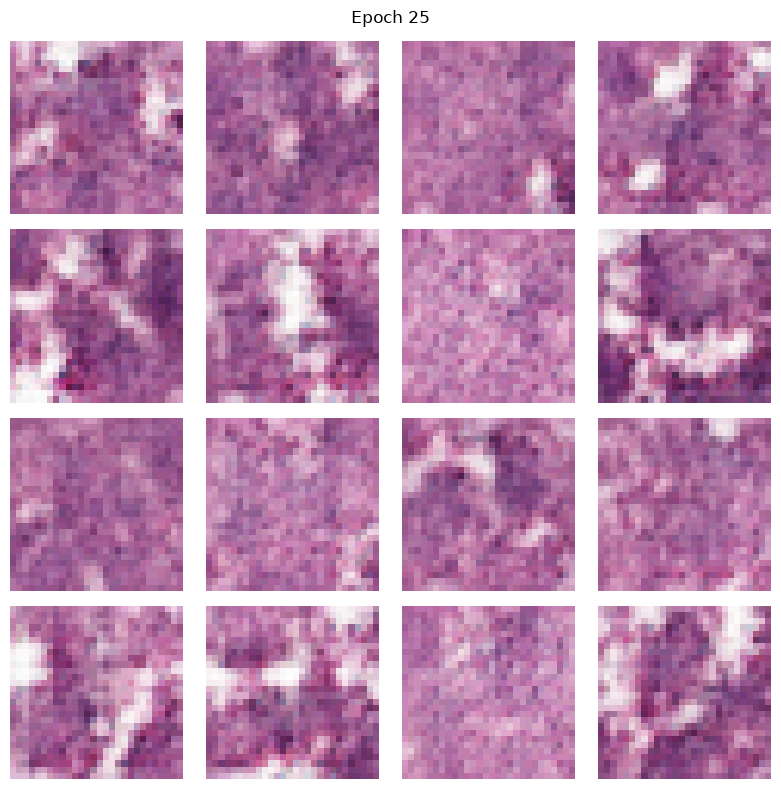

Epoch 26/30 | G Loss: 0.7052 | D Loss: 1.3832
Epoch 27/30 | G Loss: 0.7030 | D Loss: 1.3874
Epoch 28/30 | G Loss: 0.7024 | D Loss: 1.3835
Epoch 29/30 | G Loss: 0.7037 | D Loss: 1.3826
Epoch 30/30 | G Loss: 0.7038 | D Loss: 1.3859


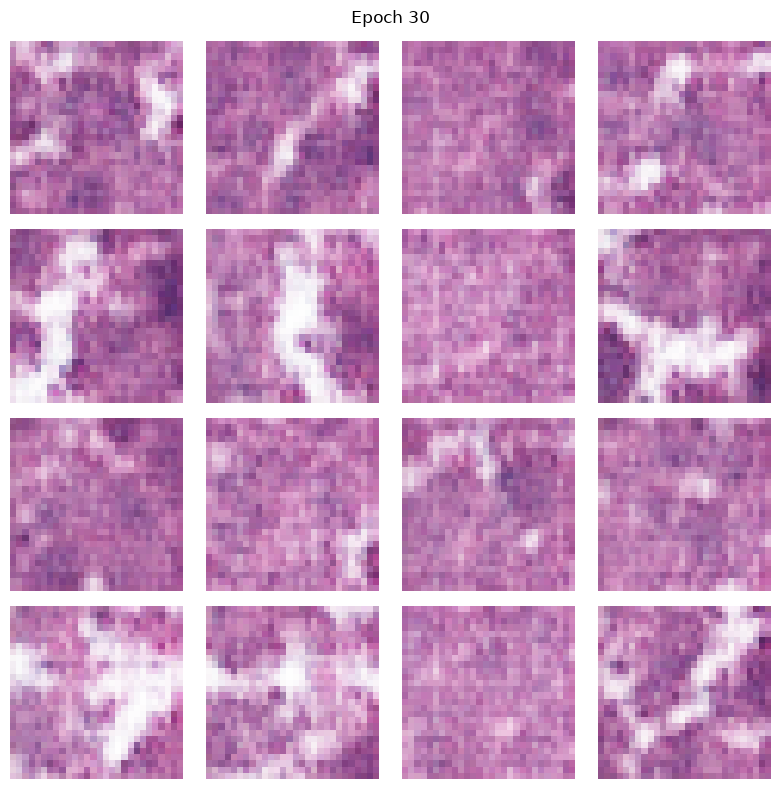

In [26]:
for epoch in range(20, 30):

    gen_metric = keras.metrics.Mean()
    disc_metric = keras.metrics.Mean()

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        gen_metric.update_state(g_loss)
        disc_metric.update_state(d_loss)

    epoch_g_loss = float(gen_metric.result())
    epoch_d_loss = float(disc_metric.result())

    history["generator_loss"].append(epoch_g_loss)
    history["discriminator_loss"].append(epoch_d_loss)

    print(
        f"Epoch {epoch + 1}/30 | "
        f"G Loss: {epoch_g_loss:.4f} | "
        f"D Loss: {epoch_d_loss:.4f}"
    )

    if (epoch + 1) % 5 == 0:

        generate_save_images(
            generator,
            epoch + 1,
            fixed_noise
        )

        manager.save(checkpoint_number=epoch + 1)

Let's compare real and generated images with 30 epoch generator

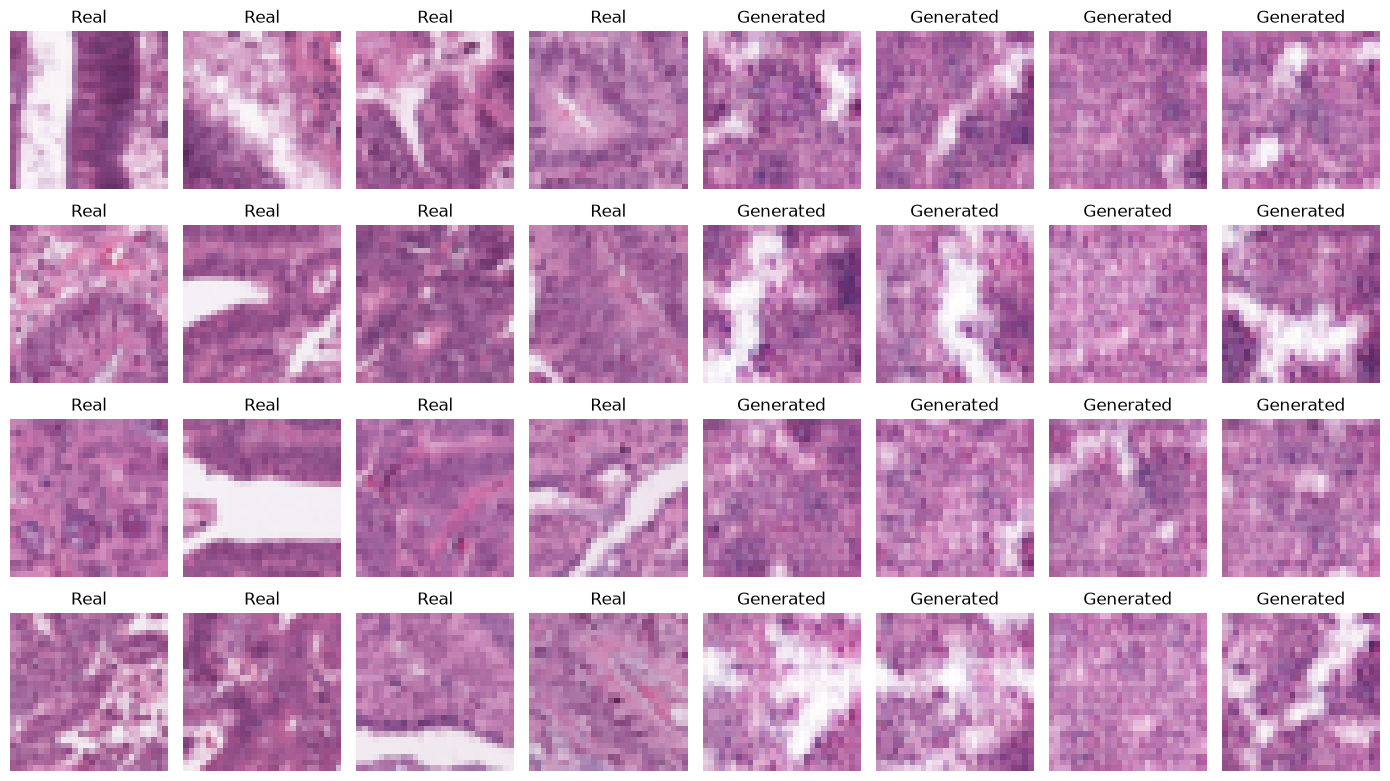

In [27]:
# Generate 16 images.
generated = generator(
    fixed_noise,
    training=False
).numpy()

generated = np.clip((generated + 1) / 2, 0, 1)

# Select 16 real images.
rng = np.random.default_rng(SEED)

indices = rng.choice(
    len(X_train_raw),
    size=16,
    replace=False
)

real = X_train_raw[indices]

# Display side by side.
fig, axes = plt.subplots(4, 8, figsize=(14, 8))

for i in range(16):

    axes[i // 4, i % 4].imshow(real[i])
    axes[i // 4, i % 4].set_title("Real")
    axes[i // 4, i % 4].axis("off")

    axes[i // 4, 4 + i % 4].imshow(generated[i])
    axes[i // 4, 4 + i % 4].set_title("Generated")
    axes[i // 4, 4 + i % 4].axis("off")

plt.tight_layout()
plt.show()

In [28]:
checkpoint = tf.train.Checkpoint(
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer
)

manager = tf.train.CheckpointManager(
    checkpoint,
    "./checkpoints/pathmnist_baseline",
    max_to_keep=3
)

manager.save(checkpoint_number=30)

'./checkpoints/pathmnist_baseline\\ckpt-30'

In [29]:
#For loading the checkpoint
latest = manager.latest_checkpoint

if latest:
    status = checkpoint.restore(latest)
    status.assert_existing_objects_matched()
    print("Restored:", latest)
else:
    print("No checkpoint found.")

Restored: ./checkpoints/pathmnist_baseline\ckpt-30


## Nearest Neighbor analysis

In [30]:

# Generate 16 images.
generated = generator(
    fixed_noise,
    training=False).numpy()

real_flat = X_train.reshape(len(X_train), -1)
generate_flat = generated.reshape(len(generated), -1)
# Find nearest real training images.
nn_model = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

nn_model.fit(real_flat)



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


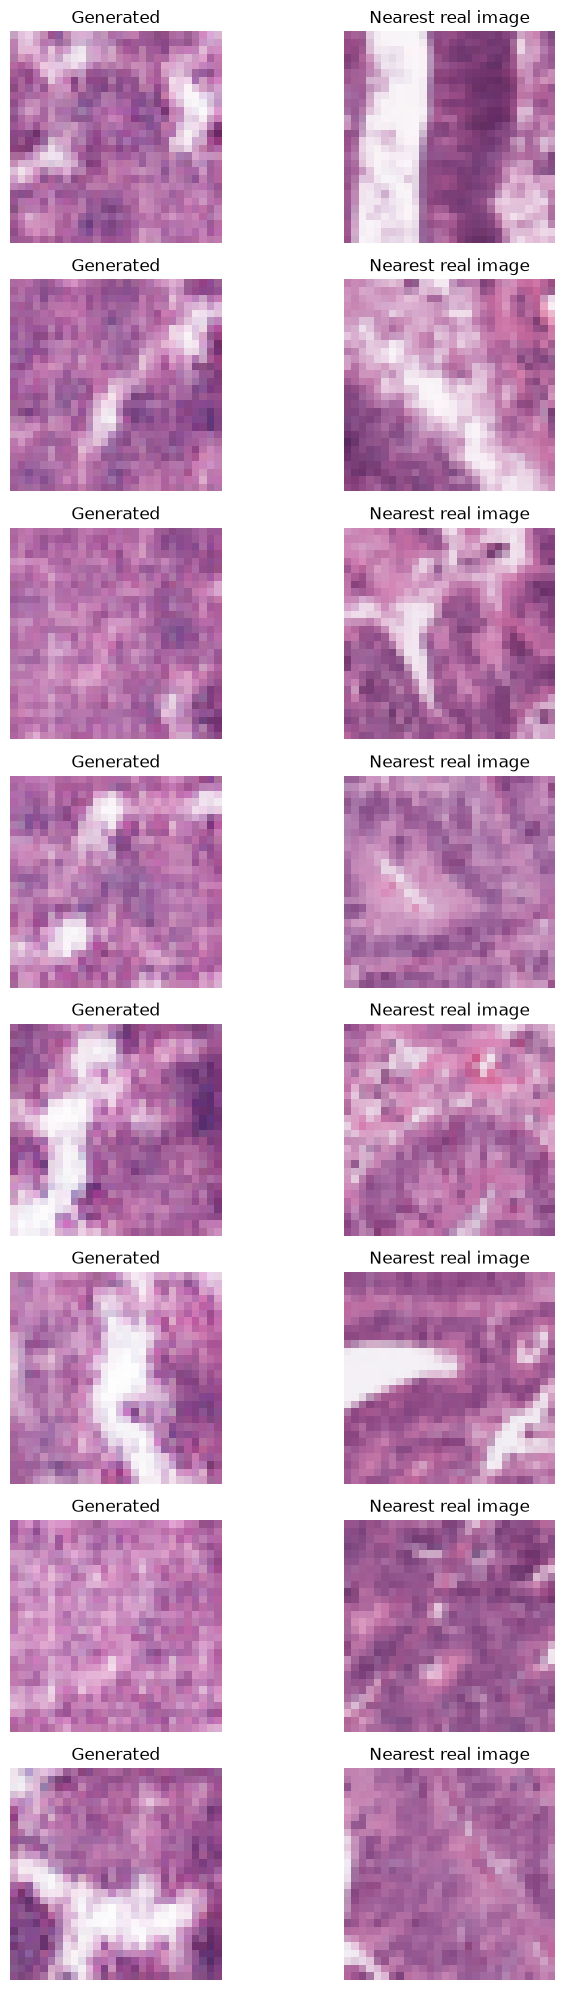

In [31]:
nearest_real = X_train_raw[indices]

fig, axes = plt.subplots(8 , 2 , figsize = (8 , 20))

for i in range(8):

    # Generated image.
    axes[i, 0].imshow(
        np.clip((generated[i] + 1) / 2, 0, 1)
    )
    axes[i, 0].set_title("Generated")
    axes[i, 0].axis("off")

    # Nearest real training image.
    axes[i, 1].imshow(nearest_real[i])
    axes[i, 1].set_title("Nearest real image")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

After looking at the nearest real image for each generated image, and seeing that they are different, it doesn't seem to memorize the images and are trying to come up with geniune images.